# 2차 실험: 입력 표현 바꾸기 (특성 블록 추가 · 교체 · 차원 축소)

| 항목 | 내용 |
|---|---|
| 목적 | 1차 상위 모델(RandomForest, LightGBM, XGBoost)을 고정하고, 입력 표현을 바꿔 F1이 오르는지 확인한다 |
| 기준(base) | Day1 1,042컬럼 — 1차 결과를 그대로 불러와 비교 (같은 fold, 같은 하이퍼파라미터) |
| 분할 | `../common/splits.csv` 고정 (개발 6,400행, 5-fold × 2회), 테스트 1,600행은 사용 안 함 |
| 비교 | 모델별로 base와 fold별 짝지은 보정 t-검정 |

| 변형 | 내용 | 근거 (1차 인사이트) |
|---|---|---|
| +rdkit217 | base + RDKit 전체 descriptor 217개 (정리 후) | 연속형 특성의 컬럼당 기여가 Fingerprint의 10~45배 |
| +mordred | base + Mordred 2D descriptor 1,613개 (정리 후) | 같은 근거, 더 넓은 물리·화학 정보 |
| +ptfp | base + PTFP 1,024비트 (정리 후) | Day1에서 고정 설정으로만 확인 |
| +maccs | base + MACCS 167비트 | 화학자가 정의한 부분구조 키, 다른 종류의 구조 정보 |
| +ap_tt | base + Atom-pair · Topological torsion count | 원자 간 거리·비틀림 정보, ECFP와 다른 관점 |
| count_chiral | ECFP·FCFP 비트를 count + 입체 정보 Fingerprint로 교체 | 처음 보는 구조에서 정답률 0.74, Day1 라벨 충돌은 입체 정보 때문 |
| combined | 위에서 효과가 있었던 블록을 모두 합침 | 자동 선택 (아래 규칙) |
| svd | Fingerprint 비트를 TruncatedSVD 256차원으로 줄임 (fold 안에서 fit) | 차원 축소 — 트리보다 SVM·MLP에서 효과 기대 |

블록 정리 규칙(라벨 미사용, 개발 세트로만 계산): 연속형은 결측 20% 초과·상수·기존 연속형과 |상관| ≥ 0.95 제거, Fingerprint형은 0이 아닌 비율 2~98%만 남기고 완전 중복 제거.

실행 방법: `build_features.py`를 먼저 한 번 실행해 `cache/`를 만든다(약 10분). 이후 노트북을 위에서부터 실행(약 25~30분). `RUN_CV = False`면 저장된 결과만 불러온다.

In [1]:
import sys, time, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import TruncatedSVD
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb, xgboost as xgb

HERE = Path.cwd()
sys.path.insert(0, str(HERE.parent / "common"))
from preprocess import preprocess_train, load_feature_columns
from evaluate import load_splits, run_cv, summarize, corrected_paired_ttest
import featurize as F

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
RES = HERE / "results"; RES.mkdir(exist_ok=True)
CACHE = HERE / "cache"
EXP01 = HERE.parent / "exp01_model_comparison" / "results"
RUN_CV = True
SEED, N_JOBS = 0, 2

## 1. 데이터 · 분할 · 특성 블록 불러오기

In [2]:
df, X, y, groups = preprocess_train(HERE.parent.parent / "train.csv")
cols = load_feature_columns()
df = load_splits(df)
idx = pd.read_parquet(CACHE / "index.parquet")
assert (idx["SMILES"].values == df["SMILES"].values).all(), "cache 순서가 다름 — build_features.py 재실행"

dev = (df["set"] == "dev").values
yd = y[dev]
folds = df.loc[dev, ["fold_r0", "fold_r1"]].reset_index(drop=True)
base = X[dev].reset_index(drop=True).astype("float32")
fp_base = [c for c in cols if c.startswith(("ecfp_", "fcfp_"))]
cont_base = [c for c in cols if c not in fp_base and c not in ("is_salt", "has_stereo_tag")]

raw = {b: F.read_cache(CACHE, b)[dev].reset_index(drop=True)
       for b in ["rdkit217", "mordred", "ptfp", "maccs", "ap_tt", "ecfp_cnt", "fcfp_cnt"]}
print("개발 세트:", base.shape, {k: v.shape[1] for k, v in raw.items()})

개발 세트: (6400, 1042) {'rdkit217': 217, 'mordred': 1613, 'ptfp': 1024, 'maccs': 167, 'ap_tt': 4096, 'ecfp_cnt': 2048, 'fcfp_cnt': 2048}


In [3]:
blocks, spec, rows = {}, {}, []
for b, d in raw.items():
    kind = "cont" if b in F.CONT_BLOCKS else "fp"
    keep, med = F.filter_block(d, kind, ref_cont=base[cont_base] if kind == "cont" else None)
    blocks[b] = F.apply_filter(d, keep, med).astype("float32")
    spec[b] = {"kind": kind, "columns": keep, "median": med}
    rows.append((b, kind, d.shape[1], len(keep)))
json.dump(spec, open(RES / "block_spec.json", "w"))
display(pd.DataFrame(rows, columns=["블록", "종류", "원래 컬럼 수", "정리 후"]).set_index("블록"))

,종류,원래 컬럼 수,정리 후
블록,,,
rdkit217,cont,217,168
mordred,cont,1613,700
ptfp,fp,1024,751
maccs,fp,167,125
ap_tt,fp,4096,1655
ecfp_cnt,fp,2048,566
fcfp_cnt,fp,2048,368


## 2. 변형 정의와 모델

In [4]:
nonfp_base = [c for c in cols if c not in fp_base]
variants = {
    "+rdkit217": pd.concat([base, blocks["rdkit217"]], axis=1),
    "+mordred": pd.concat([base, blocks["mordred"]], axis=1),
    "+ptfp": pd.concat([base, blocks["ptfp"]], axis=1),
    "+maccs": pd.concat([base, blocks["maccs"]], axis=1),
    "+ap_tt": pd.concat([base, blocks["ap_tt"]], axis=1),
    "count_chiral": pd.concat([blocks["ecfp_cnt"], blocks["fcfp_cnt"], base[nonfp_base]], axis=1),
}
print({k: v.shape[1] for k, v in variants.items()})

ALGOS = {
    "RandomForest": lambda: RandomForestClassifier(n_estimators=500, max_features="sqrt", n_jobs=N_JOBS, random_state=SEED),
    "LightGBM": lambda: lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, colsample_bytree=0.3,
                                           subsample=0.8, subsample_freq=1, verbose=-1, random_state=SEED, n_jobs=N_JOBS),
    "XGBoost": lambda: xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8,
                                         colsample_bytree=0.3, tree_method="hist", eval_metric="logloss",
                                         random_state=SEED, n_jobs=N_JOBS),
}

{'+rdkit217': 1210, '+mordred': 1742, '+ptfp': 1793, '+maccs': 1167, '+ap_tt': 2697, 'count_chiral': 949}


## 3. 교차검증 (변형 × 모델)

In [5]:
def run_variant(vname, Xv, algos, store):
    for a, mk in algos.items():
        t0 = time.time()
        s, o = run_cv(mk, Xv, yd, folds, f"{vname}|{a}")
        store["scores"].append(s)
        for r in o.columns:
            store["oof"][f"{vname}|{a}|{r}"] = o[r].values
        print(f"{vname:14s} {a:12s} F1 {s.f1.mean():.4f} ± {s.f1.std(ddof=0):.4f} | AUC {s.auc.mean():.4f} | {time.time()-t0:4.0f}s", flush=True)

# base는 1차 결과를 재사용 (같은 fold·같은 하이퍼파라미터)
s1 = pd.read_csv(EXP01 / "cv_scores.csv"); o1 = pd.read_csv(EXP01 / "oof_predictions.csv")
base_scores = s1[s1.model.isin(list(ALGOS) + ["SVM_RBF", "MLP"])].copy()
base_scores["model"] = "base|" + base_scores["model"]
base_oof = {f"base|{c}": o1[c].values for c in o1.columns if "|" in c and c.split("|")[0] in list(ALGOS) + ["SVM_RBF", "MLP"]}

if RUN_CV:
    store = {"scores": [base_scores], "oof": dict(base_oof)}
    for vname, Xv in variants.items():
        run_variant(vname, Xv, ALGOS, store)

+rdkit217      RandomForest F1 0.8148 ± 0.0083 | AUC 0.8740 |   53s


+rdkit217      LightGBM     F1 0.8122 ± 0.0074 | AUC 0.8754 |   33s


+rdkit217      XGBoost      F1 0.8115 ± 0.0073 | AUC 0.8751 |   46s


+mordred       RandomForest F1 0.8106 ± 0.0090 | AUC 0.8640 |  150s


+mordred       LightGBM     F1 0.8114 ± 0.0074 | AUC 0.8722 |   78s


...

+ap_tt         LightGBM     F1 0.8180 ± 0.0078 | AUC 0.8786 |   74s


+ap_tt         XGBoost      F1 0.8160 ± 0.0070 | AUC 0.8758 |   99s


count_chiral   RandomForest F1 0.8191 ± 0.0069 | AUC 0.8766 |   41s


count_chiral   LightGBM     F1 0.8143 ± 0.0085 | AUC 0.8745 |   21s


count_chiral   XGBoost      F1 0.8113 ± 0.0064 | AUC 0.8713 |   32s


### 3-1. combined: 효과가 있었던 블록 합치기
- 규칙: 세 모델의 base 대비 F1 변화 평균이 +0.002 이상인 추가 블록을 모두 합친다.
- count_chiral이 기준을 넘으면 ECFP·FCFP 비트를 count 버전으로 바꾼 상태에서 합친다.

In [6]:
if RUN_CV:
    sc = pd.concat(store["scores"], ignore_index=True)
    sc[["variant", "algo"]] = sc.model.str.split("|", expand=True)
    mean_f1 = sc.groupby(["variant", "algo"]).f1.mean().unstack()
    delta = (mean_f1 - mean_f1.loc["base"]).mean(axis=1).drop("base")
    good = [v for v in delta.index if delta[v] >= 0.002]
    print("base 대비 평균 ΔF1:", delta.round(4).to_dict()); print("합칠 변형:", good)
    use_cnt = "count_chiral" in good
    parts = [blocks["ecfp_cnt"], blocks["fcfp_cnt"], base[nonfp_base]] if use_cnt else [base]
    parts += [blocks[v[1:]] for v in good if v.startswith("+")]
    if len(good) >= 2:
        variants["combined"] = pd.concat(parts, axis=1)
        print("combined 컬럼 수:", variants["combined"].shape[1])
        run_variant("combined", variants["combined"], ALGOS, store)
    json.dump({"good": good, "use_count_chiral": use_cnt}, open(RES / "combined_rule.json", "w"))

base 대비 평균 ΔF1: {'+ap_tt': 0.0011, '+maccs': 0.0017, '+mordred': -0.0024, '+ptfp': 0.0012, '+rdkit217': -0.0024, 'count_chiral': -0.0003}
합칠 변형: []


### 3-2. 차원 축소 (TruncatedSVD)
- Fingerprint 비트 1,027개를 256차원으로 줄이고, 연속형 15개는 표준화해 그대로 붙인다. SVD와 표준화 모두 fold 안에서 fit한다.
- 트리 모델은 원래 비트 단위 분할에 강해 효과가 적을 것으로 보고, SVM·MLP(1차 6·7위)와 LightGBM을 비교한다.

In [7]:
def svd_pipe(est):
    pre = ColumnTransformer([("svd", TruncatedSVD(256, random_state=SEED), fp_base),
                             ("sc", StandardScaler(), [c for c in cols if c not in fp_base])])
    return make_pipeline(pre, est)

SVD_ALGOS = {
    "SVM_RBF": lambda: svd_pipe(SVC(C=1.0, kernel="rbf", gamma="scale", random_state=SEED)),
    "MLP": lambda: svd_pipe(MLPClassifier((128,), alpha=1e-3, early_stopping=True, max_iter=200, random_state=SEED)),
    "LightGBM": lambda: svd_pipe(lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, colsample_bytree=0.3,
                                                    subsample=0.8, subsample_freq=1, verbose=-1, random_state=SEED, n_jobs=N_JOBS)),
}
if RUN_CV:
    run_variant("svd", base, SVD_ALGOS, store)
    scores = pd.concat(store["scores"], ignore_index=True)
    oof = pd.DataFrame(store["oof"]); oof.insert(0, "SMILES", df.loc[dev, "SMILES"].values); oof.insert(1, "label", yd)
    scores.to_csv(RES / "cv_scores.csv", index=False); oof.to_csv(RES / "oof_predictions.csv", index=False)
else:
    scores = pd.read_csv(RES / "cv_scores.csv"); oof = pd.read_csv(RES / "oof_predictions.csv")
scores[["variant", "algo"]] = scores.model.str.split("|", expand=True)

svd            SVM_RBF      F1 0.7983 ± 0.0074 | AUC 0.8557 |   39s


svd            MLP          F1 0.8008 ± 0.0062 | AUC 0.8581 |   19s


svd            LightGBM     F1 0.8000 ± 0.0055 | AUC 0.8578 |   34s


## 4. 결과

In [8]:
f1_tbl = scores.groupby(["variant", "algo"]).f1.mean().unstack()
auc_tbl = scores.groupby(["variant", "algo"]).auc.mean().unstack()
ncol = {"base": len(cols), **{k: v.shape[1] for k, v in variants.items()}, "svd": 256 + 15}
order_v = ["base"] + [v for v in f1_tbl.index if v != "base"]
f1_tbl = f1_tbl.loc[order_v]; auc_tbl = auc_tbl.loc[order_v]

# 모델별 base 대비 짝지은 검정
tests = []
for a in f1_tbl.columns:
    sub = scores[scores.algo == a].copy(); sub["model"] = sub["variant"]
    if "base" not in set(sub.model): continue
    t = corrected_paired_ttest(sub, "base"); t["algo"] = a; tests.append(t.reset_index())
tests = pd.concat(tests).rename(columns={"model": "variant"})
tests.to_csv(RES / "paired_ttest_vs_base.csv", index=False)

show = f1_tbl.copy()
show.insert(0, "컬럼 수", [ncol.get(v, np.nan) for v in show.index])
show["트리 3개 평균"] = f1_tbl[["RandomForest", "LightGBM", "XGBoost"]].mean(axis=1)
show.to_csv(RES / "f1_by_variant.csv")
print("F1 (10 fold 평균)")
display(show.round(4).style.background_gradient(subset=["트리 3개 평균"], cmap="Blues").format(precision=4, na_rep="-"))
print("base 대비 차이와 보정 짝지은 t-검정 p값")
piv = tests.pivot(index="variant", columns="algo", values="diff_vs_best").round(4).astype(str) + " (p=" + \
      tests.pivot(index="variant", columns="algo", values="p_value").round(3).astype(str) + ")"
display(piv.loc[[v for v in order_v if v in piv.index]])

F1 (10 fold 평균)


algo,컬럼 수,LightGBM,MLP,RandomForest,SVM_RBF,XGBoost,트리 3개 평균
variant,,,,,,,
base,1042,0.8150,0.7962,0.8177,0.8040,0.8131,0.8152
+ap_tt,2697,0.8180,-,0.8150,-,0.8160,0.8164
+maccs,1167,0.8178,-,0.8190,-,0.8142,0.8170
+mordred,1742,0.8114,-,0.8106,-,0.8165,0.8128
+ptfp,1793,0.8185,-,0.8155,-,0.8153,0.8164
+rdkit217,1210,0.8122,-,0.8148,-,0.8115,0.8128
count_chiral,949,0.8143,-,0.8191,-,0.8113,0.8149
svd,271,0.8000,0.8008,-,0.7983,-,0.8000


base 대비 차이와 보정 짝지은 t-검정 p값


algo,LightGBM,MLP,RandomForest,SVM_RBF,XGBoost
variant,,,,,
+ap_tt,0.0031 (p=0.4),NaN,-0.0027 (p=0.492),NaN,0.0029 (p=0.602)
+maccs,0.0028 (p=0.443),NaN,0.0013 (p=0.666),NaN,0.0011 (p=0.781)
+mordred,-0.0036 (p=0.339),NaN,-0.0071 (p=0.25),NaN,0.0034 (p=0.366)
+ptfp,0.0035 (p=0.194),NaN,-0.0022 (p=0.328),NaN,0.0022 (p=0.687)
+rdkit217,-0.0028 (p=0.336),NaN,-0.0028 (p=0.583),NaN,-0.0016 (p=0.775)
count_chiral,-0.0007 (p=0.862),NaN,0.0015 (p=0.592),NaN,-0.0017 (p=0.603)
svd,-0.015 (p=0.002),0.0045 (p=0.34),NaN,-0.0057 (p=0.057),NaN


## 5. 시각화

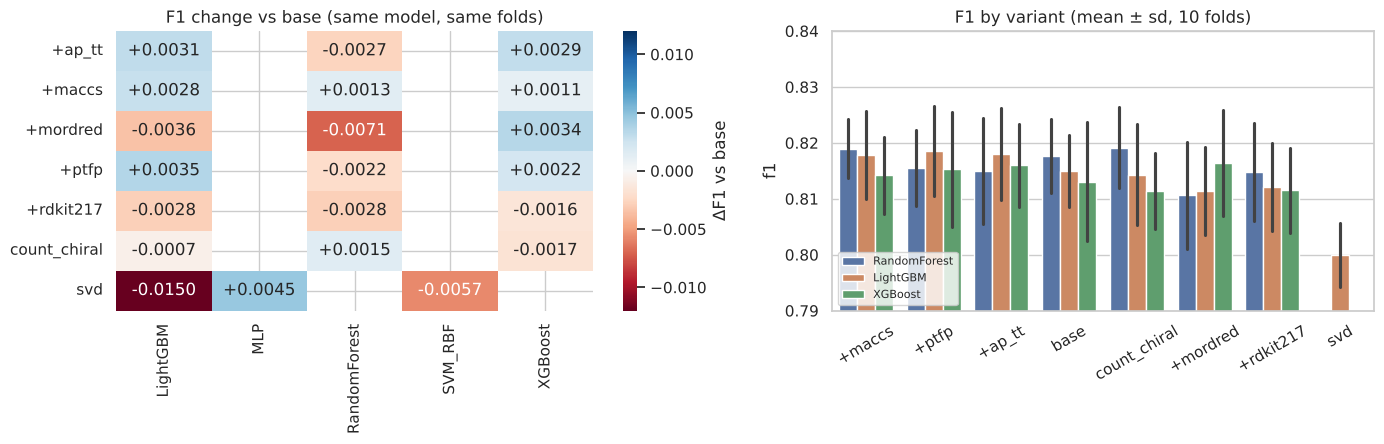

In [9]:
d = (f1_tbl - f1_tbl.loc["base"]).drop("base")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(d, annot=True, fmt="+.4f", cmap="RdBu", center=0, vmin=-0.012, vmax=0.012, ax=ax[0], cbar_kws={"label": "ΔF1 vs base"})
ax[0].set_title("F1 change vs base (same model, same folds)"); ax[0].set_xlabel(""); ax[0].set_ylabel("")
m = scores[scores.algo.isin(["RandomForest", "LightGBM", "XGBoost"])]
order_bar = f1_tbl[["RandomForest", "LightGBM", "XGBoost"]].mean(axis=1).dropna().sort_values(ascending=False).index
sns.barplot(data=m, x="variant", y="f1", hue="algo", order=order_bar, ax=ax[1], errorbar="sd")
ax[1].set_ylim(0.79, 0.84); ax[1].set_xlabel(""); ax[1].set_title("F1 by variant (mean ± sd, 10 folds)"); ax[1].tick_params(axis="x", rotation=30)
ax[1].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(RES / "fig_variant_f1.png", dpi=130); plt.show()

### 5-1. 처음 보는 구조에서 나아졌는가
1차에서 학습 데이터와 유사도가 낮을수록 정답률이 떨어졌다. 가장 좋은 변형이 그 구간을 개선했는지 본다.

In [10]:
tree_mean = f1_tbl[["RandomForest", "LightGBM", "XGBoost"]].mean(axis=1).drop("base")
best_v = tree_mean.idxmax()
best_a = f1_tbl.loc[best_v, ["RandomForest", "LightGBM", "XGBoost"]].idxmax()
print("가장 좋은 변형:", best_v, "/", best_a)
# 3·4차에서 쓰도록 변형별 컬럼 목록과 최고 변형 저장 (svd는 파이프라인이라 base 컬럼)
vc = {"base": list(cols), **{k: list(v.columns) for k, v in variants.items()}}
best_nonsvd = tree_mean.drop("svd", errors="ignore").idxmax()
json.dump({"best_variant": best_nonsvd, "tree_mean_f1": tree_mean.round(4).to_dict(), "columns": vc},
          open(RES / "variant_columns.json", "w"))

E = df.loc[dev, [f"ecfp_{i}" for i in range(1024)]].values.astype(np.float32); cnt = E.sum(1)
max_sim = np.zeros(len(E)); f0 = folds["fold_r0"].values
for k in range(5):
    va, tr = f0 == k, f0 != k
    inter = E[va] @ E[tr].T
    max_sim[va] = (inter / (cnt[va][:, None] + cnt[tr][None, :] - inter + 1e-9)).max(1)
lab = ["<0.5", "0.5-0.7", "0.7-0.8", "≥0.8"]
b = pd.cut(max_sim, [0, 0.5, 0.7, 0.8, 1.01], labels=lab, right=False)
acc = pd.DataFrame({
    f"base|{best_a}": [((oof[f"base|{best_a}|r0"] >= .5).astype(int) == yd)[b == l].mean() for l in lab],
    f"{best_v}|{best_a}": [((oof[f"{best_v}|{best_a}|r0"] >= .5).astype(int) == yd)[b == l].mean() for l in lab],
    "화합물 수": [int((b == l).sum()) for l in lab]}, index=lab)
acc["차이"] = acc.iloc[:, 1] - acc.iloc[:, 0]
display(acc.round(3))

가장 좋은 변형: +maccs / RandomForest


,base|RandomForest,+maccs|RandomForest,화합물 수,차이
<0.5,0.737,0.744,680,0.007
0.5-0.7,0.770,0.774,1266,0.004
0.7-0.8,0.779,0.780,2062,0.001
≥0.8,0.839,0.839,2392,0.000


### 5-2. 앙상블 재료로서의 가치 (4차 미리보기)
- 다른 입력으로 학습한 모델이 base 모델과 얼마나 다르게 예측하는지(순위 상관), 그리고 둘을 평균하면 F1이 어떻게 되는지 본다.

In [11]:
ref = f"base|{best_a}"
rows = []
for c in sorted({c.rsplit("|", 1)[0] for c in oof.columns if "|" in c}):
    if c == ref: continue
    p0 = np.mean([oof[f"{c}|r{r}"] for r in (0, 1)], axis=0)
    rho = pd.Series(oof[f"{c}|r0"]).corr(pd.Series(oof[f"{ref}|r0"]), method="spearman")
    single = np.mean([f1_score(yd, oof[f"{c}|r{r}"] >= .5) for r in (0, 1)])
    pair = np.mean([f1_score(yd, (oof[f"{c}|r{r}"] + oof[f"{ref}|r{r}"]) / 2 >= .5) for r in (0, 1)]) if "SVM" not in c else np.nan
    rows.append((c, rho, single, pair))
ens = pd.DataFrame(rows, columns=["모델", f"{ref}와 순위 상관", "단독 F1", f"{ref}와 평균 F1"]).set_index("모델")
ref_f1 = np.mean([f1_score(yd, oof[f"{ref}|r{r}"] >= .5) for r in (0, 1)])
print(f"{ref} 단독 F1: {ref_f1:.4f}")
display(ens.sort_values(f"{ref}와 평균 F1", ascending=False).round(4))

base|RandomForest 단독 F1: 0.8177


,base|RandomForest와 순위 상관,단독 F1,base|RandomForest와 평균 F1
모델,,,
+ap_tt|LightGBM,0.9373,0.8180,0.8219
+ptfp|LightGBM,0.9439,0.8185,0.8202
+maccs|LightGBM,0.9420,0.8178,0.8199
+mordred|RandomForest,0.9254,0.8105,0.8197
+mordred|XGBoost,0.9174,0.8165,0.8197
+ap_tt|RandomForest,0.9712,0.8150,0.8197
+rdkit217|RandomForest,0.9669,0.8148,0.8196
+maccs|RandomForest,0.9904,0.8190,0.8192
base|LightGBM,0.9423,0.8150,0.8192


## 6. 결론과 3차로 넘길 것

결과 표는 4절, 그래프는 5절 참고.

### 판단
1. 가설 1은 기각됐다. descriptor를 늘려도(RDKit 217, Mordred 700) 오르지 않고 오히려 평균 0.0024 낮아졌다.
   - 1차에서 연속형 변수의 gain이 컸던 건 clogp·TPSA·MolWt 같은 핵심 변수 몇 개 덕분이었다.
   - 이 변수들은 이미 base에 들어 있다. 새 descriptor는 대부분 이와 겹치거나 노이즈가 되어, 컬럼 샘플링(30%)에서 핵심 변수가 뽑힐 기회를 줄인 것으로 보인다.
2. 가설 2도 거의 효과가 없었다.
   - 입체 정보를 반영한 count Fingerprint는 RandomForest에서만 +0.0015였다.
   - 유사도 0.5 미만 구간의 정답률도 +maccs에서 0.737 → 0.744로 조금 오른 정도다.
3. 차원 축소는 트리에는 해롭다(LightGBM −0.015, 유의). 비트 하나하나로 나누는 트리의 장점이 사라진다. MLP에서만 약간 올랐지만 유의하지 않다.
4. 결론적으로 입력 표현은 포화 상태에 가깝다. 구조가 거의 같은 화합물(유사도 0.9 이상)끼리도 라벨 일치율이 0.81이었던 것과 같은 맥락이다.

### 앙상블 재료로서의 가치 (4차 근거)
- 다른 입력으로 학습한 모델은 base RandomForest와 예측 순위 상관이 0.91~0.94다. 같은 입력의 다른 트리(0.94~0.98)보다 서로 다르다.
- base RandomForest와 단순 평균한 결과: +ap_tt LightGBM 0.8219(+0.0042), +ptfp LightGBM 0.8202, +mordred XGBoost 0.8197.
- 1차에서 같은 입력끼리 섞었을 때(+0.0015)보다 효과가 크다. 4차에서 입력이 다른 모델들을 섞는 방향이 가장 유망하다.

### 3차로 넘길 것
- 튜닝할 입력: +maccs (트리 3개 평균 F1 최고, 1,167컬럼). 차이가 작아서 컬럼이 적고 계산이 빠른 것도 장점이다.
- 4차 앙상블 후보: +ap_tt·+ptfp·+mordred 모델처럼 입력이 다른 모델의 OOF 예측 (`results/oof_predictions.csv`)

### 제출 파일
- `predict_output_임채현_2차.csv`: 2차 단일 최고 (count_chiral × RandomForest, CV F1 0.8191)를 8,000행 전체로 재학습해 예측했다. 테스트 세트(1,600행) F1 0.8208, AUC 0.875 (1차 RandomForest 테스트 F1 0.813).

